
## Monte Carlo Option Pricing

This notebook implements Monte Carlo pricing for European options under risk-neutral geometric Brownian motion. Estimates are compared against Black–Scholes, with convergence analysed through empirical RMSE. Antithetic and control variates are then introduced to reduce estimation variance.

In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [2]:
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.2
N = 100000

In [3]:
def terminal_price(Z, S0, T, r, sigma):

    return S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z)


def option_payoff(St, K, option):

    if option == "call":
        return np.maximum(St - K, 0)
    elif option == "put":
        return np.maximum(K - St, 0)
    else:
        raise ValueError("Option bust be 'call' or 'put'")


def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2


def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

### Standard Monte Carlo Pricing


### Standard Monte Carlo Pricing

Under risk-neutral GBM, terminal stock prices are simulated using

$$
S_T=S_0e^{(r-\frac12\sigma^2)T+\sigma\sqrt{T}Z},\qquad Z\sim\mathcal{N}(0,1).
$$

European option prices are estimated by averaging and discounting the simulated payoffs:

$$
\hat V_N=e^{-rT}\frac{1}{N}\sum_{i=1}^{N}f(S_T^{(i)}).
$$

The estimator is unbiased and converges to the Black–Scholes price as $N\to\infty$.


In [4]:
rng = np.random.default_rng(7)

Z = rng.normal(0, 1, N)
St = terminal_price(Z, S0, T, r, sigma)

call_payoff = option_payoff(St, K, "call")
put_payoff = option_payoff(St, K, "put")

call_price = np.exp(-r*T) * np.mean(call_payoff)
put_price = np.exp(-r*T) * np.mean(put_payoff)

print("Call Price:", call_price)
print("Put Price:", put_price)

Call Price: 10.40666378166819
Put Price: 5.5641383356515215


In [5]:
lhs = call_price - put_price
rhs = S0 - K * np.exp(-r*T)

parity_error = abs(lhs - rhs)

print("LHS:", lhs)
print("RHS:", rhs)
print("Parity Error:", parity_error)

LHS: 4.842525446016668
RHS: 4.877057549928594
Parity Error: 0.03453210391192574



The simulated prices approximately satisfy put-call parity, with the remaining discrepancy arising from Monte Carlo sampling error.



**Standard Errors and Confidence Intervals**

The estimated standard error of the Monte Carlo price is

$$
\widehat{SE}=\frac{e^{-rT}s_f}{\sqrt{N}},
$$

where $s_f$ is the sample standard deviation of the simulated payoffs.

An approximate 95% confidence interval is

$$
\hat V_N\pm1.96\widehat{SE}.
$$


In [6]:
c = 0.95
s = - norm.ppf((1 - c) / 2).round(3)
print(s)

1.96


In [7]:
for option, payoffs in [("Call", call_payoff), ("Put", put_payoff)]:

    price = np.exp(-r * T) * np.mean(payoffs)

    sigma_estimate = np.std(payoffs, ddof = 1)
    SE_estimate = np.exp(-r * T) * sigma_estimate / np.sqrt(N)

    CI = [price - 1.96 * SE_estimate, price + 1.96 * SE_estimate]

    print(f"{option} | Price: {price:.4f} | SE: {SE_estimate:.4f} | 95% CI: [{CI[0]:.4f}, {CI[1]:.4f}]")

Call | Price: 10.4067 | SE: 0.0464 | 95% CI: [10.3158, 10.4975]
Put | Price: 5.5641 | SE: 0.0274 | 95% CI: [5.5105, 5.6178]



### Monte Carlo Convergence

Monte Carlo convergence is assessed by comparing simulated call prices against the analytical Black–Scholes value for increasing sample sizes.

The Central Limit Theorem gives the asymptotic standard error

$$
SE(\hat V_N)=\frac{\sigma_V}{\sqrt{N}}=O(N^{-1/2}),
$$

where $\sigma_V$ is the standard deviation of the discounted payoff.

To measure empirical convergence, the root mean squared error (RMSE) is estimated across $M$ independent experiments:

$$
\operatorname{RMSE}(N)=\sqrt{\frac1M\sum_{j=1}^{M}(\hat V_N^{(j)}-V_{BS})^2}.
$$


In [8]:
bs_price, _ = black_scholes_price(S0, K, T, r, sigma)
print(bs_price)

10.450583572185565


In [9]:
n_values = np.logspace(2, 5, 50, dtype=int)
rng = np.random.default_rng(7)
M = 100

errors = []
estimates = []

for n in n_values:

    Z = rng.normal(0, 1, size = (M,n))
    St = terminal_price(Z, S0, T, r, sigma)
    payoffs = option_payoff(St, K, "call")

    prices = np.exp(-r*T) * np.mean(payoffs, axis = 1)
    
    estimates.append(np.mean(prices))
    errors.append(np.sqrt(np.mean((prices - bs_price)**2)))

reference = np.exp(-r*T) * np.std(payoffs, ddof=1) / np.sqrt(n_values)


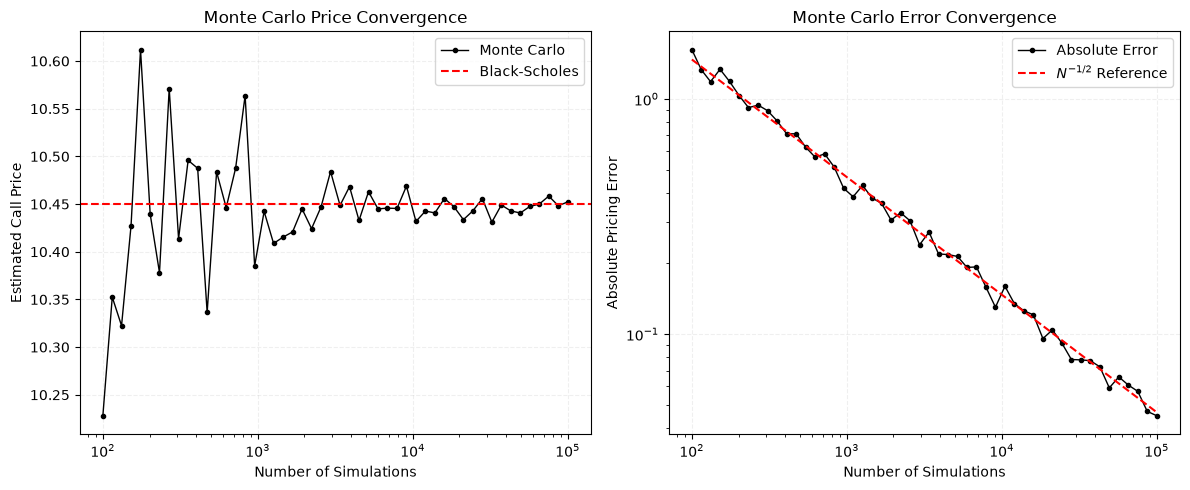

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Monte Carlo price convergence
axs[0].plot(n_values, estimates, color="black",
            linewidth = 1, marker = ".", label = "Monte Carlo")

axs[0].axhline(bs_price, color="red",
               linestyle = "--", label = "Black-Scholes")

axs[0].set_xscale("log")
axs[0].set_xlabel("Number of Simulations")
axs[0].set_ylabel("Estimated Call Price")
axs[0].set_title("Monte Carlo Price Convergence")
axs[0].legend()
axs[0].grid(alpha = 0.2, linestyle = "--")

# Absolute pricing error
axs[1].plot(n_values, errors, color = "black",
            linewidth = 1, marker = ".", label = "Absolute Error")

axs[1].plot(n_values, reference, color = "red",
            linestyle = "--", linewidth = 1.5,
            label = r"$N^{-1/2}$ Reference")

axs[1].set_xscale("log")
axs[1].set_yscale("log")
axs[1].set_xlabel("Number of Simulations")
axs[1].set_ylabel("Absolute Pricing Error")
axs[1].set_title("Monte Carlo Error Convergence")
axs[1].grid(True, which = "major", alpha = 0.2, linestyle = "--")
axs[1].legend()

plt.tight_layout()
plt.show()


The Monte Carlo estimates approach the Black–Scholes price as the sample size increases, with progressively smaller fluctuations. Empirical RMSE follows the expected $O(N^{-1/2})$ convergence rate, confirming that reducing estimation error by a factor of two requires approximately four times as many simulations.



### Antithetic Variates

Antithetic variates reduce estimation variance by pairing each standard normal sample $Z_i$ with $-Z_i$.

The paired payoff is

$$
A_i=\frac{f(S_T^{(+Z_i)})+f(S_T^{(-Z_i)})}{2}.
$$

The negative covariance between paired payoffs reduces the variance of their average without changing the expected option price.


In [11]:
n_values = np.unique(2 * (np.logspace(2, 5, 50, dtype=int) // 2))
rng = np.random.default_rng(4)
M = 100

errors_antithetic = []
estimates_antithetic = []

for n in n_values:

    Z = rng.normal(0, 1, size = (M, n//2))

    Stx = terminal_price(Z, S0, T, r, sigma)
    Sty = terminal_price(-Z, S0, T, r, sigma)

    x = option_payoff(Stx, K, "call")
    y = option_payoff(Sty, K, "call")

    paired_payoffs = (x + y) / 2

    prices = np.exp(-r*T) * np.mean(paired_payoffs, axis = 1)

    estimates_antithetic.append(np.mean(prices))
    errors_antithetic.append(np.sqrt(np.mean((prices - bs_price)**2)))


### Control Variates

Control variates reduce estimation variance by exploiting a correlated variable with a known expectation.

Using the discounted terminal stock price as the control, the adjusted estimator is

$$
\hat V_{CV}=\bar X+\hat\beta(S_0-\bar Y),
$$

where $X=e^{-rT}f(S_T)$ and $Y=e^{-rT}S_T$, so that $\mathbb{E}[Y]=S_0$ under the risk-neutral measure.

The variance-minimising coefficient is

$$
\beta^*=\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(Y)}.
$$

This coefficient is estimated using an independent pilot sample before applying the adjustment to the Monte Carlo estimates.


In [12]:
rng = np.random.default_rng(4)

# Estimate beta using an independent pilot sample
Z_pilot = rng.normal(0, 1, 50000)

St_pilot = terminal_price(Z_pilot, S0, T, r, sigma)

X_pilot = np.exp(-r * T) * option_payoff(St_pilot, K, "call")
Y_pilot = np.exp(-r * T) * St_pilot

beta = np.cov(X_pilot, Y_pilot)[0, 1] / np.var(Y_pilot, ddof=1)

# Control variate simulation
errors_control = []
estimates_control = []

for n in n_values:

    Z = rng.normal(0, 1, (M, n))

    St = terminal_price(Z, S0, T, r, sigma)

    X = np.exp(-r * T) * option_payoff(St, K, "call")
    Y = np.exp(-r * T) * St

    prices = np.mean(X, axis = 1) + beta * (S0 - np.mean(Y, axis = 1))

    estimates_control.append(np.mean(prices))
    errors_control.append(np.sqrt(np.mean((prices - bs_price) ** 2)))


### Variance Reduction Comparison

The three estimators are compared using empirical RMSE across $M$ independent experiments at each sample size.

The improvement is measured by the MSE reduction factor:

$$
R=\frac{\operatorname{MSE}_{\text{standard}}}{\operatorname{MSE}_{\text{reduced}}}
=\left(\frac{\operatorname{RMSE}_{\text{standard}}}{\operatorname{RMSE}_{\text{reduced}}}\right)^2.
$$

A larger value of $R$ indicates a greater reduction in estimation error.


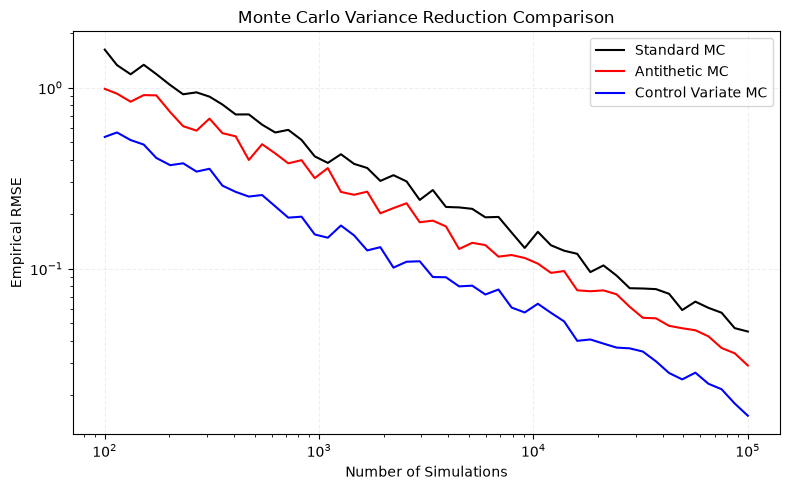

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(n_values, errors,
         color="black", linewidth=1.5,
         label="Standard MC")

plt.plot(n_values, errors_antithetic,
         color="red", linewidth=1.5,
         label="Antithetic MC")

plt.plot(n_values, errors_control,
         color="blue", linewidth=1.5,
         label="Control Variate MC")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of Simulations")
plt.ylabel("Empirical RMSE")
plt.title("Monte Carlo Variance Reduction Comparison")

plt.grid(True, which="major", alpha=0.2, linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
idx = np.argmin(np.abs(n_values - 10000))

factor_antithetic = (errors[idx] / errors_antithetic[idx])**2
factor_control = (errors[idx] / errors_control[idx])**2

print("Antithetic Variate MSE Reduction:", factor_antithetic)
print("Control Variate MSE Reduction:", factor_control)

Antithetic Variate MSE Reduction: 2.2444689129068696
Control Variate MSE Reduction: 6.230726841920065


In [15]:
idx = np.argmin(np.abs(n_values - 10000))

factor_antithetic = (errors[idx] / errors_antithetic[idx]) ** 2
factor_control = (errors[idx] / errors_control[idx]) ** 2

print(f"Sample size: {n_values[idx]}")
print(f"Antithetic MSE reduction: {factor_antithetic:.1f}x")
print(f"Control variate MSE reduction: {factor_control:.1f}x")

Sample size: 10480
Antithetic MSE reduction: 2.2x
Control variate MSE reduction: 6.2x



Both variance-reduction methods decrease empirical RMSE while preserving the expected option price. At approximately 10,000 simulations, antithetic variates reduce MSE by a factor of 2.2, compared with 6.2 for control variates.

The control-variate method achieves the greater reduction in this experiment, although its independent pilot sample introduces additional computational cost.



### Conclusion

Monte Carlo pricing was implemented and validated against the analytical Black–Scholes solution. Empirical RMSE followed the expected $O(N^{-1/2})$ convergence rate, demonstrating the relationship between sample size and estimation accuracy.

Both antithetic and control variates reduced estimation error, with control variates achieving the greater reduction in these experiments. These methods demonstrate how Monte Carlo accuracy can be improved without increasing the main simulation sample size.
